> **Recommended: run this notebook in Google Colab, nothing to install.**
>
> [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/zerocarbonshipping/navigate-zcs/blob/workshop-colab/docs/examples/south-pacific.ipynb)
>
> Just click on the "Open in Colab" button and follow along. Click the ▶ button on each cell (or press Shift+Enter) to see the results and move on to the next one.
>
> If you can't or don't want to use Colab, the documentation website shows the pre-run results.

# Island trade in the South Pacific

[Regional networks](https://zerocarbonshipping.github.io/navigate-zcs/workshop-preview/examples/regional-networks.html) · deck `simulations/examples/example_2/`

Can a regional bulk trade switch to biodiesel when only its main ports supply it?

## The case

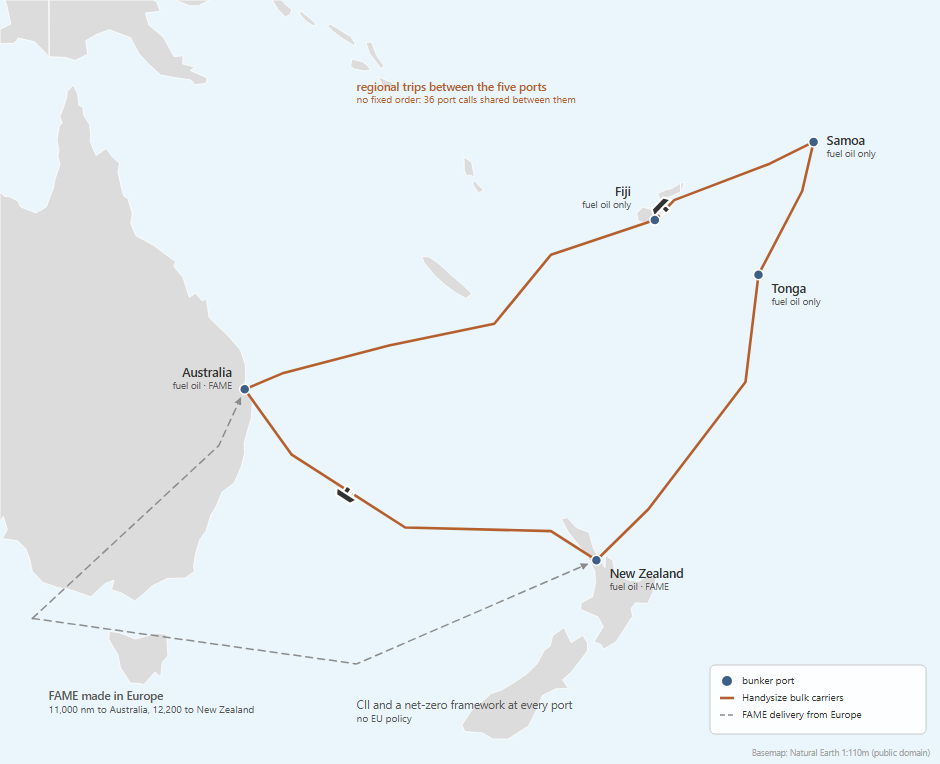

- **Ships:** 6 Handysize bulk carriers (~26,000 DWT), all on fuel oil, the same
  design throughout: the oil engine can burn biodiesel (FAME) instead. The
  owners can fit seven efficiency measures.
- **Route:** regional trips between Australia, New Zealand, Fiji, Samoa and Tonga,
  with no fixed order of calls. Trade grows 5 % a year.
- **Fuels:** fuel oil at every port; FAME made from used cooking oil in Europe,
  shipped 11,000 to 12,200 nm, and bunkered in Australia and New Zealand only.
- **Policy:** CII and a net-zero framework on every port, the framework with
  values that are the deck's own, not the data library's. No EU policy.
- **Horizon:** 2026 to 2050, yearly.

## Results

In [1]:
# @title Setup
# Setup. Works both on Google Colab and in a local checkout of the repository.
import os
from pathlib import Path


# The branch these notebooks live on, and the one Colab clones. The "Open in
# Colab" badge at the top of the notebook, like the links between the
# notebooks, opens the copy on the workshop-colab branch instead: the same
# notebooks with their outputs cleared, rebuilt from this branch by
# .github/workflows/workshop-colab.yml. Change BRANCH, and that workflow, to
# "main" once the branch has been merged.
BRANCH = "dev-workshop"


def at_repo_root() -> bool:
    """True if the working directory is the root of the repository."""
    return Path("navigate").is_dir() and Path("assumptions").is_dir()


if at_repo_root():
    print("Already at the repository root.")
elif Path("../../navigate").is_dir():
    # Local Jupyter starts the kernel in the notebook's own folder,
    # docs/workshop/, but the paths below are relative to the repository root.
    os.chdir("../..")
    print("Moved up to the repository root.")
else:
    # Colab, or any other fresh environment
    if not Path("navigate-zcs").is_dir():
        !git clone --depth 1 -b {BRANCH} https://github.com/zerocarbonshipping/navigate-zcs.git
    os.chdir("navigate-zcs")
    print("Cloned the repository and moved into it.")

assert at_repo_root(), f"not at the repository root: {Path.cwd()}"

# `import navigate` is not a usable test here: from the repository root it
# succeeds because the source folder is present, even when the `navigate`
# command itself is missing.
import sys
from importlib.metadata import PackageNotFoundError, version

try:
    print(f"Navigate {version('navigate-zcs')} is already installed.")
except PackageNotFoundError:
    %pip install -q .
    print("Installed Navigate.")


# The example deck.
EXAMPLE = Path("simulations/examples/example_2")
assert EXAMPLE.is_dir(), (
    f"{EXAMPLE} not found under {Path.cwd()}. On Colab the setup cell clones the "
    f"{BRANCH!r} branch, so this deck has to be committed and pushed there."
)


Moved up to the repository root.
Navigate 1.0.0 is already installed.


The cell below solves the case from 2026 to 2050 and draws its well-to-wake emissions, its freight rate and the fuel it burns.

Truncated initial technology shares for vessel 'bulk_carrier_handysize_oil' across 25 age increment(s): lighting_system_bulk_carrier_handy, propeller_improvement_devices_bulk_carrier_handy, variable_frequency_drive_bulk_carrier_handy
No technology cost of capital supplied for Fleet("bulk_carrier_handysize"), using vessel cost of capital. This will likely lead to a higher uptake of technologies.


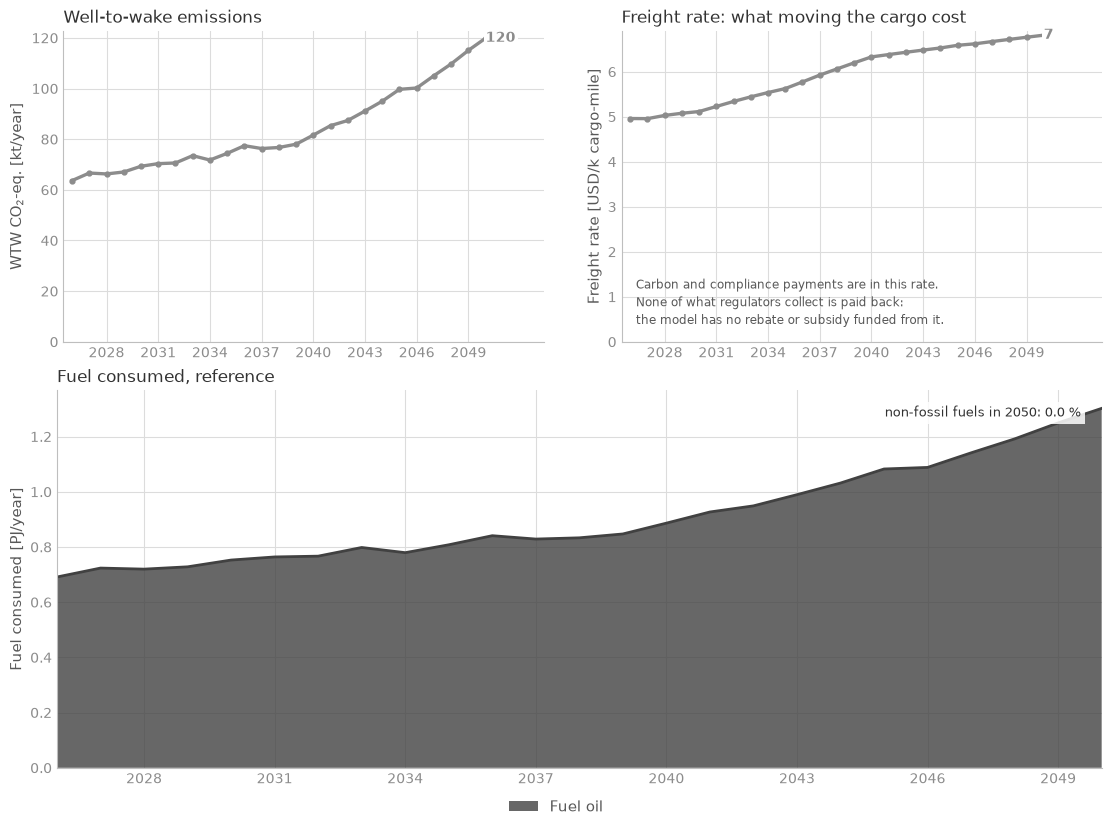

In [2]:
# @title Run the case and see the results
import sys
from pathlib import Path

import matplotlib.pyplot as plt

# The workshop's figure and the functions that fill it, shared with the
# Examples pages: docs/workshop/_results.py.
sys.path.insert(0, str(Path("docs/workshop").resolve()))
from _results import compare_with_previous, plot_cases, print_summary, run_case, scale, summarise
from _solver import guard_interior_point

guard_interior_point()

NAV = Path("simulations/examples/example_2/example_2.nav")
REF_TWEAK = None
_m = run_case(NAV)
ref = summarise(_m)
plot_cases({"reference": ref}, annotate=True)
plt.show()


# ===========================================================================
#  The machinery for the sensitivity analysis. Nothing to edit here: the
#  levers are further down.
# ===========================================================================
# each lever, and the forecasts it multiplies
LEVERS = {
    "OIL_PRICE": ['fossil_fuel_oil_price_global'],
    "COOKING_OIL_COST": ['used_cooking_oil_cost_europe'],
}
_RUNS = []      # the scenarios solved so far, newest last: (levers, summary)


def run_your_scenario():
    """Solve the levers set in the YOUR SCENARIO cell and compare with
    the reference and with the scenario solved before it."""
    changed = [(n, globals()[n]) for n in LEVERS if globals()[n] != 1.0]
    if not changed:
        print("Every lever is still at 1.0, so this would just re-solve the deck.")
        print("Change one of the numbers above and run this cell again.")
        return
    tweaks = ([REF_TWEAK] if REF_TWEAK else []) + [scale(f, v) for n, v in changed
                                                   for f in LEVERS[n]]

    def your_scenario(m):
        for t in tweaks:
            t(m)

    label = ",  ".join(f"{n} x {v}" for n, v in changed)
    compare_with_previous(NAV, ref, your_scenario, label, _RUNS, ref_label="reference")
    plt.show()


### Move one lever

Each number multiplies what the deck already says, so 1.0 is the reference. Set one, run the cell, and compare with the reference and with the scenario you ran before. As an example, OIL_PRICE is set to 2.0: the fuel oil price doubled.

Truncated initial technology shares for vessel 'bulk_carrier_handysize_oil' across 25 age increment(s): lighting_system_bulk_carrier_handy, propeller_improvement_devices_bulk_carrier_handy, variable_frequency_drive_bulk_carrier_handy
No technology cost of capital supplied for Fleet("bulk_carrier_handysize"), using vessel cost of capital. This will likely lead to a higher uptake of technologies.


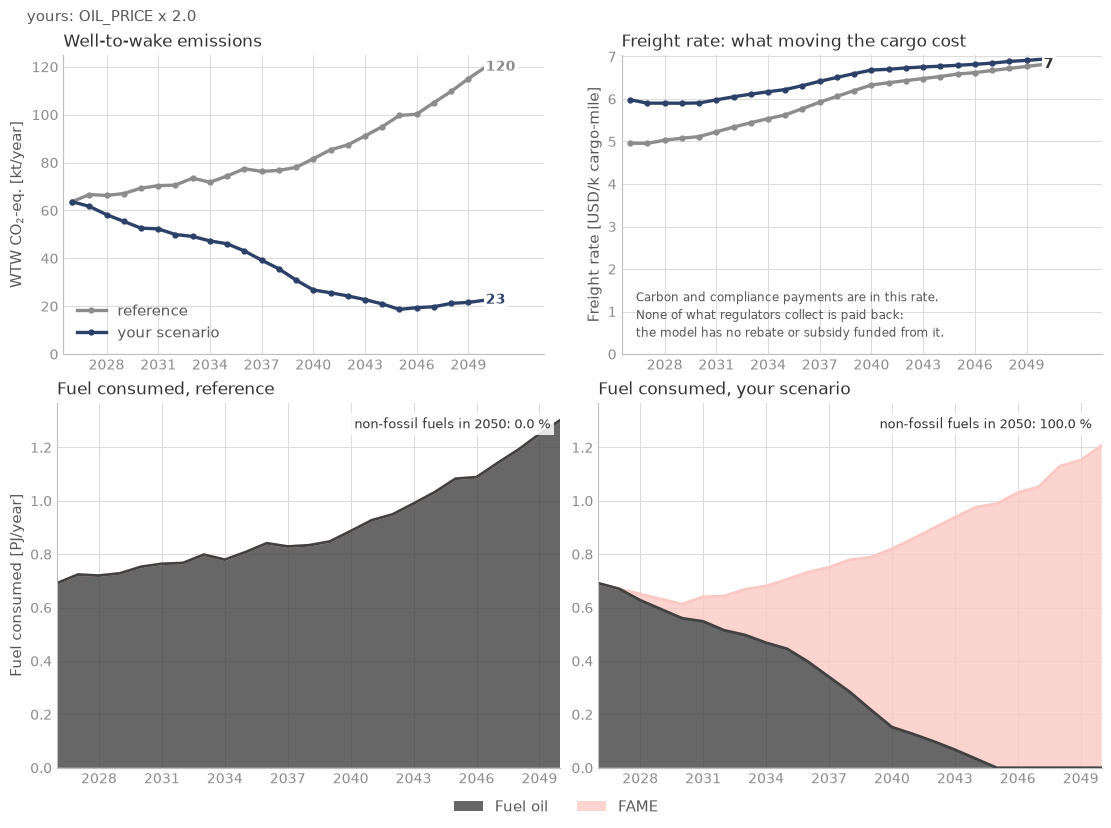

In [3]:
# ===========================================================================
#  YOUR SCENARIO.  Set a lever, then run this cell: it solves your scenario
#  and compares it with the reference and with the scenario you ran before it.
#
#  Every number is a MULTIPLIER on what the deck already says, so 1.0 is the
#  deck. The right-hand column says what each 1.0 is worth, so you can judge
#  whether a factor of two is a big change or a small one.
#
#  As an example, OIL_PRICE is set to 2.0: the fuel oil price doubled.
#  Set OIL_PRICE back to 1.0 to start from the deck.
#
#                           suggested span  what 1.0 means in the deck
OIL_PRICE        = 2.0   #  0.7 - 2.0       485 USD/t, flat to 2050
COOKING_OIL_COST = 1.0   #  0.25 - 2.0      1,130 USD/t of the used cooking oil FAME is made from, flat
# ===========================================================================

run_your_scenario()


## The deck

In [4]:
# @title The deck, tab by tab
import sys
from pathlib import Path

sys.path.insert(0, str(Path("docs/workshop").resolve()))
from _deck import show_deck

show_deck(EXAMPLE, {
    "example_2.nav": ['example_2.nav'],
    "Fleet": ['includes/fleet.inc', 'includes/energy_efficiencies.inc', 'includes/fleet_curves.inc', 'includes/energy_efficiencies_curves.inc'],
    "Route": ['includes/route.inc', 'includes/ports.inc', 'includes/bunker_logistics.inc'],
    "Fuel": ['includes/fuel_production.inc', 'includes/regions.inc', 'includes/producer.inc'],
    "Regulation": ['includes/cii.inc', 'includes/net_zero_framework.inc'],
    "Decisions": ['includes/decision_processes.inc'],
})


# ---- example_2.nav ----
# SPDX-FileCopyrightText: 2026 Fonden Mærsk Mc-Kinney Møller Center for Zero Carbon Shipping
# SPDX-License-Identifier: CC-BY-4.0

# ---------------------------------------------------------------------------------
#
# SETTING THE SCENE – EXAMPLE 2 (PACIFIC BULK TRADE WITH FAME)
#
# A regional bulk carrier operator based in Australia and New Zealand operates 
# a small fleet of Handysize bulk carriers trading across the South
# Pacific (Australia, New Zealand, Fiji, Samoa, and Tonga).
#
# The fleet is modeled with a single vessel specification, which can operate 
# on either fossil marine fuels or renewable alternatives such as
# B100-grade FAME. FAME is assumed to be produced from waste oils under 
# recognized sustainability schemes, with supply available at the main ports 
# in Australia and New Zealand. Smaller island ports are assumed to provide 
# only fossil fuels, requiring planning of bunkering logistics.
#
# EU regulatory measures are excluded. Only international/IMO frameworks are 
# considered (e.g., CII and potential IMO market-based measures).
#
# This scenario provides a reference case for assessing the costs and emission 
# impacts of adopting FAME in Pacific regional bulk trades. Users can adjust 
# fleet size, routing, fuel availability, costs, emission factors, and 
# regulatory assumptions in the .inc files to explore sensitivities and
# alternative policy outcomes.
#
# ---------------------------------------------------------------------------------


DEFINE {

    # -------------------------- DEFINITIONS --------------------------
    # Import the default model settings. These provide baseline constants
    # and parameters that can be overwritten in this scenario.
    Load DefaultModelDefinition

    # ---------------------- BUNKER LOGISTICS -------------------------
    # Defines the cost and handling assumptions for transporting and supplying
    # fuels. This is particularly relevant as FAME is produced in Europe and
    # shipped to the South Pacific, while fossil fuels are treated as widely
    # available regionally.
    Include "includes/bunker_logistics.inc"

    # ---------------------------- FLEET ------------------------------
    # Defines the vessel type used, size, age structure, and initial uptake
    # of the operator’s fleet. This section also includes optional energy
    # efficiency measures.
    Include "includes/fleet_curves.inc"
    Include "includes/fleet.inc"
    Include "includes/energy_efficiencies_curves.inc"
    Include "includes/energy_efficiencies.inc"

    # ----------------------------- ROUTE -----------------------------
    # Defines the ports included in the example (Australia, New Zealand, and
    # selected Pacific island ports) along with their characteristics. The
    # route file specifies the distribution of voyages, port calls, and
    # time allocation between sea and port conditions.
    Include "includes/route.inc"
    Include "includes/ports.inc"

    # ----------------------------- FUEL ------------------------------
    # Defines the fuels available in the example, their production processes,
    # feedstocks, costs, and emission factors. Regional differences and
    # producer-specific constraints (e.g. feedstock limits) are also captured
    # here.
    Include "includes/fuel_production.inc"
    Include "includes/regions.inc"
    Include "includes/producer.inc"
    Load DefaultEmission

    # -------------------------- REGULATION ---------------------------
    # Defines the relevant international regulatory frameworks affecting the
    # fleet, such as IMO’s CII, long-term net-zero pathways, and related
    # measures. EU-specific policies are excluded in this Pacific scenario.
    Include "includes/cii.inc"
    Include "includes/net_zero_framework.inc"

    # ----------------------- DECISION PROCESESS --------------------
    Include "includes/decision_processes.inc"
	
	# -------------------------- OUTPUT ----------------------

## Build it with an AI assistant

The prompt below rebuilds this deck exactly: an assistant that saw only the
prompt reproduced its results. The deck's own numbers are in it as the person's
numbers, marked GIVEN, so they are not a source. Ships on trips between several
ports in no fixed order, some ports without the new fuel, start from it.
[Session 5](https://zerocarbonshipping.github.io/navigate-zcs/workshop-preview/workshop/05-build-your-own-case.html) shows how to use it.

<details>
<summary>Full prompt for this case</summary>

<!-- tested-prompt: 8b9bc47414f4 -->
**The study.** A regional bulk trade between Australia, New Zealand, Fiji, Samoa
and Tonga, 2026 to 2050, yearly steps, in one run. Six Handysize bulk carriers
call at the five ports in no fixed order. They can burn biodiesel (FAME) in their
oil engines, but FAME is made in Europe and sold only in Australia and New
Zealand. The question is whether the trade switches to FAME under a net-zero
framework when only its main ports supply it. The prompt rebuilds
`simulations/examples/example_2` exactly.

**What comes from the library.** The ship class (`bulk_carrier_26k_dwt_ice_oil`),
its seven efficiency measures, the fuels, the FAME plant and process, the fuel
oil price, and every cost and emission Forecast the deck names.

**What is GIVEN.** Every other number is the deck's own, given in the prompt as
the person's numbers: the fleet of six ships and its ages, the route, the
handling costs, the delivery distances, the FAME feedstock ceiling, and the CII
and net-zero framework values. They are not sourced: compare runs of this deck
with each other, not with the region's real totals.

**Limits.** Six ships are a few ships, not a market segment: Navigate decides in
fractions of ships. The net-zero framework uses the deck's own values, not the
library's.

**Tested:** 2026-10-30, built cold on Sonnet and on Haiku: both decks ran with
the same 25 warnings as example_2 (2 unique, both expected) and reproduce its
results: fuel oil only, 63.7 kt CO2e in 2026, 74.4 in 2035 and 119.9 in 2050.
The plant then gained the library's cost of capital (it was financed at 0 %;
no FAME is made, so nothing moves), and the wording was fixed from the
builders' notes; built cold again on Haiku, it gives the same results.

````text
You are helping me build a simulation study for Navigate, the shipping
decarbonisation model. Write the files yourself; do not only
describe them.

Before writing anything, find the Navigate repository on my machine (a folder
usually named navigate-zcs; ask me where it is if you cannot find it), then read
docs/workshop/building-a-deck.md in it and follow it. It
says how Navigate works, how to run a deck and read its results, and the rules
every deck follows. This prompt gives the case.

Every number below is mine: use it as given and mark it GIVEN. The fleet is six
ships on purpose. You should not need to invent anything: if you would have to,
the prompt is missing it, so say so. Where this prompt and building-a-deck.md
disagree, this prompt wins.

THE DECK
A new folder, simulations/user/south_pacific/, holding south_pacific.nav and its
includes/ folder, one file per part below (bunker_logistics, fleet_curves, fleet,
energy_efficiencies_curves, energy_efficiencies, route, ports, fuel_production,
regions, producer, cii, net_zero_framework, decision_processes), included in
that order from DEFINE.

THE CASE
A regional bulk trade in the South Pacific, 2026 to 2050, yearly steps, one run.
- .nav DEFINE: Load DefaultModelDefinition first, then the includes, with
  Load DefaultEmission after producer and Load DefaultPlot at the end. EVENTS:
  Load DefaultTimeStepYearly. No DefaultBunkerLogistics, no DefaultRegulation, no
  DefaultCalibration (decision_processes.inc holds the deck's own), no other
  policy. You may add Load DefaultReport to read the results.

FLEET
- Copy Vessel "bulk_carrier_26k_dwt_ice_oil" to "bulk_carrier_handysize_oil".
  No other design: the ships run on fuel oil or FAME in the same engine.
- Fleet "bulk_carrier_handysize": that one vessel; InitialVessels = 6;
  InitialSplit = [1.]; InitialAgeDistribution =
  [Curve("age_dist_bulk_carrier_handysize_oil")], a list of one: ages 0 to 24, with 0.167 at ages 3, 11,
  15, 16, 17 and 21, and 0 at every other age; TradeGrowth = 0.05;
  AllowSpeedManagement = TRUE; MaximumSpeedChange = 0.5. No orderbook, no
  set_fuel_conversion_cost.
- Technologies, the library's seven for this class: air_lubrication,
  exhaust_gas_boiler_ae, flettner_rotor, hull_painting, lighting_system,
  propeller_improvement_devices and variable_frequency_drive, each named
  <measure>_bulk_carrier_handy.
- Initial technology shares, set_initial_technology_share("*", <technology>,
  Curve), each a Curve "uptake_<technology>" flat from 0 to 30 (two rows):
  exhaust_gas_boiler_ae 0.125, hull_painting 0.1, lighting_system 0.5,
  propeller_improvement_devices 0.25, variable_frequency_drive 0.25. None for
  air lubrication and the Flettner rotor.
- Decision sensitivities: InterFuelSensitivity 0.5, IntraFuelSensitivity 0.5,
  TechnologySensitivity 2.

ROUTE
- Vessel "bulk_carrier_handysize_oil" { Route = Route("pacific_trade") }.
- Route "pacific_trade": REGIONAL_TRIP; Ports = Port("*"), which takes every
  port of the deck in the order they are declared, so declare the five ports
  in this order: australia, new_zealand, fiji, samoa, tonga;
  PortCalls = [11, 9, 8, 4, 4]; TimeAtSea = 0.47;
  Speeds = [13.0, 12.5, 12.0, 11.8, 12.2];
  ConditionDistribution = [0.26, 0.21, 0.18, 0.17, 0.18]. No
  CapacityUtilizations and no set_voyage_distribution: every port pair keeps
  its equal share.

PORTS
- australia and new_zealand sell FAME (fatty_acid_methyl_ester); fiji, samoa
  and tonga do not (set_bunkering_allowed FALSE).
- Port "*": fossil_fuel_oil allowed everywhere; its bunker price set with
  set_bunker_price_overwrite to Forecast("fossil_fuel_oil_price_global") and its
  well-to-tank CO2 with set_bunker_wtt_overwrite to
  Forecast("fossil_fuel_oil_wtt_carbon_dioxide"); handling cost 8 for fuel oil
  and 18 for FAME, as Variables "handling_cost_oil" and "handling_cost_fame".

BUNKER LOGISTICS
- One BunkerLogistics block: LiquidMarketFuels = [Fuel("fossil_fuel_oil")];
  set_distance europe to australia 11000 and europe to new_zealand 12200;
  set_transport_cost("*", 0.01).

FUEL PRODUCTION
- Import Fuel fossil_fuel_oil and fatty_acid_methyl_ester; Import Plant
  plant_fatty_acid_methyl_ester and set its Region to europe and its Source to
  grid, and its CostOfCapital to Forecast cost_of_capital_plant_bio_europe.
- Import Process fatty_acid_methyl_ester_synthesis; Import Feedstock
  used_cooking_oil, methanol_grey and demineralized_water; Import Source grid.
- Region "europe": set_source_opex("grid", Forecast("electricity_cost_europe_mid"))
  and set_source_wtt("grid", "carbon_dioxide", Forecast("grid_emissions_europe")).
- Region "*": set_transport_cost("truck", 0.0) and set_transport_wtt("truck",
  "carbon_dioxide", Forecast("truck_emissions")); feedstock costs
  demineralized_water_cost and used_cooking_oil_cost_europe; for
  fatty_acid_methyl_ester_synthesis the process capex, opex and energy
  Forecasts of the same names (fatty_acid_methyl_ester_synthesis_capex, _opex,
  _energy), and its well-to-tank: carbon_dioxide =
  <-Variable("carbon_dioxide_per_fame") + Forecast("fame_wtt_carbon_dioxide")>,
  methane = fame_wtt_methane, nitrous_oxide = fame_wtt_nitrous_oxide. Then an
  empty Transport "truck" { } node.
- Producer "producer_fame": Plants = [plant_fatty_acid_methyl_ester];
  MaximumDevelopment = 1; set_feed_constraint("used_cooking_oil",
  Forecast("used_cooking_oil_constraint")), that Forecast being 2.80e4 in 2025,
  3.30e4 in 2030, 3.70e4 in 2035, 3.90e4 in 2040, 4.10e4 in 2045, 4.20e4 in 2050
  (dates "01-01-<year>"), Extrapolate = LINEAR. FuelDemandSensitivity 1.25,
  FuelCostSensitivity 0.5.

POLICY
Both Regulations have Jurisdiction = the five ports and
set_include_vessel("*", TRUE).
- Regulation "cii": Measure TRANSPORT_NOMINAL, Scheme INDIVIDUAL, Scope TTW,
  IncludeSlip FALSE, Emissions carbon_dioxide, Fuels all, RemedialCost = 0 (it
  only tracks compliance). set_fuel_ttw carbon_dioxide: fossil_fuel_oil 3.114,
  fatty_acid_methyl_ester 0.62. set_vessel_threshold("bulk_carrier_handy*",
  Forecast("cii_target_bulk_carrier_handysize")). Forecast
  "cii_target_reduction": 1.0 in 2019, then 0.99, 0.98, 0.97, 0.95, 0.93, 0.91,
  0.89, 0.87, 0.85, 0.83 and 0.81 in 2030 (01-01 each year), Extrapolate FLAT.
  Copy Forecast it to "cii_target_bulk_carrier_handysize" with Multiplier 7.08.
- Regulation "net_zero_framework": Measure INTENSITY, Scheme FLEXIBLE, Scope WTW,
  IncludeSlip TRUE, all emissions and fuels, RemedialCost =
  Forecast("net_zero_framework_remedial"), SharedThreshold =
  Forecast("net_zero_framework_z_values"). z values (Multiplier 93.3,
  Extrapolate FLAT): 1.00 on 01-01-2025 and on 31-12-2027, then 0.96 (2028),
  0.94 (2029), 0.92 (2030), 0.876 (2031), 0.832 (2032), 0.788 (2033), 0.744
  (2034), 0.70 (2035), 0.35 (2040), 0.05 (2050), each on 01-01. Remedial cost
  (Extrapolate FLAT): 0 on 01-01-2025 and on 31-12-2027, 380 from 01-01-2028.

BEFORE YOU TELL ME IT WORKS
Run the deck and report on it as building-a-deck.md says: the exit code, the
warnings and errors from the Log summary, and any "convergence status: Failure".
Then give, from the report, for 2026, 2035 and 2050: the well-to-wake emissions
(kt CO2e) and the energy by fuel (PJ). Say plainly whether any FAME is
bunkered, and remind me that the numbers are mine, not the library's.
````

</details>

## Run it yourself

In Colab: the badge at the top of this page opens it as a notebook, which runs
the deck and lets you move the levers. Nothing to install.

On your machine, install Navigate first: follow the [installation steps in the README](https://github.com/zerocarbonshipping/navigate-zcs/blob/dev-workshop/README.md#installation),
or the more detailed [Getting started](https://zerocarbonshipping.github.io/navigate-zcs/workshop-preview/tutorials/getting_started.html) tutorial.
Then run the deck from the repository root:

```bash
python -m navigate simulations/examples/example_2/example_2.nav -d ./assumptions
```

To make a case of your own, copy the folder to `simulations/user/` and change
it, or have an AI assistant build one from the prompt above, as
[Session 5](https://zerocarbonshipping.github.io/navigate-zcs/workshop-preview/workshop/05-build-your-own-case.html) shows.